# TP Final DSS · Etapa 1: Preprocesamiento

**Objetivo del TP.** Identificar perfiles de estudiantes según las problemáticas que presentan en conjunto (k-means) y ver cómo se reparten por provincia, edad, sexo y escuela, para decidir qué acción preventiva llevar a cada lugar.

**Qué hace esta etapa.** Deja la base lista para el k-means. Al final tenemos una tabla con una fila por estudiante, los 15 indicadores del modelo en 0/1 y, aparte, las variables que vamos a usar después para cruzar (provincia, escuela, edad, sexo, familia).

| Paso | Qué hacemos |
|---|---|
| 1 | Cargar la base nacional de la EMSE 2018 |
| 2 | Filtrar estudiantes de 13 a 17 años |
| 3 | Sacar la provincia y la escuela del diseño muestral |
| 4 | Pasar los 15 indicadores a 0/1 |
| 5 | Controlar contra los resultados oficiales |
| 6 | Revisar faltantes y quedarnos con las filas completas |
| 7 | Mirar la matriz de correlación (qué variables van juntas) |
| 8 | Justificar las variables que quedan afuera |
| 9 | Armar las variables de cruce |
| 10 | Exportar la base preprocesada |

## 0. Configuración

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

Definimos todo lo que es "configuración" arriba, así el resto del código no tiene números mágicos. Cada indicador del modelo tiene su columna original (`qn`), un nombre legible y la dimensión a la que pertenece. Las dimensiones son para nosotros (para leer los resultados): **el k-means no las ve**, solo ve las 15 columnas.

In [2]:
# Indicadores que entran al k-means: nombre -> (columna qn, descripción, dimensión)
VARIABLES_MODELO = {
    'soledad':          ('qn22', 'Se sintió solo casi siempre',        'Salud mental'),
    'preocupacion':     ('qn23', 'La preocupación no lo deja dormir',  'Salud mental'),
    'ideacion':         ('qn24', 'Pensó seriamente en el suicidio',    'Salud mental'),
    'plan':             ('qn25', 'Hizo un plan',                       'Salud mental'),
    'intento':          ('qn26', 'Lo intentó',                         'Salud mental'),
    'atacado':          ('qn15', 'Fue atacado físicamente',            'Violencia'),
    'peleas':           ('qn16', 'Participó en peleas',                'Violencia'),
    'bullying_escuela': ('qn66', 'Bullying en la escuela',             'Violencia'),
    'bullying_fuera':   ('qn67', 'Bullying fuera de la escuela',       'Violencia'),
    'ciberacoso':       ('qn68', 'Ciberacoso',                         'Violencia'),
    'tabaco':           ('qn29', 'Fuma tabaco',                        'Consumo'),
    'alcohol':          ('qn35', 'Toma alcohol',                       'Consumo'),
    'borrachera':       ('qn38', 'Se emborrachó alguna vez',           'Consumo'),
    'marihuana':        ('qn42', 'Consume marihuana',                  'Consumo'),
    'falta_clases':     ('qn53', 'Faltó a clases sin permiso',         'Escuela'),
}
COLUMNAS_MODELO = list(VARIABLES_MODELO)

# Provincias: dígitos 5 y 6 de stratum, en orden alfabético.
# Las marcadas como deducidas no tienen archivo propio en la OMS (hay que confirmarlas).
PROVINCIAS = {
    '01': 'Buenos Aires', '02': 'Catamarca', '03': 'Chaco', '04': 'Chubut', '05': 'CABA',
    '06': 'Córdoba', '07': 'Corrientes', '08': 'Entre Ríos', '09': 'Formosa', '10': 'Jujuy',
    '11': 'La Pampa', '12': 'La Rioja', '13': 'Mendoza', '14': 'Misiones', '15': 'Neuquén',
    '16': 'Río Negro', '17': 'Salta', '18': 'San Juan', '19': 'San Luis', '20': 'Santa Cruz',
    '21': 'Santa Fe', '22': 'Santiago del Estero', '23': 'Tierra del Fuego', '24': 'Tucumán',
}
PROVINCIAS_DEDUCIDAS = {'05', '09', '11', '15', '16', '19'}

# q1: 3 = 13 años ... 7 = 17 años
EDAD_POR_CODIGO = {3: 13, 4: 14, 5: 15, 6: 16, 7: 17}
SEXO_POR_CODIGO = {1: 'Varón', 2: 'Mujer'}

## 1. Cargar los datos

Subí `data_set.csv` (el archivo nacional de la OMS, `ARG_2018_GSHS_v01`). Si ya está en la carpeta de Colab lo toma directo, si no te abre el selector de archivos.

In [3]:
RUTA_CSV = Path('data_set.csv')

if not RUTA_CSV.exists():
    try:
        from google.colab import files
        subido = files.upload()          # elegí data_set.csv
        RUTA_CSV = Path(next(iter(subido)))
    except ImportError:
        raise FileNotFoundError('No encuentro data_set.csv en la carpeta actual')

crudo = pd.read_csv(RUTA_CSV)
print(f'{crudo.shape[0]:,} filas y {crudo.shape[1]} columnas'.replace(',', '.'))
crudo.head()

56.981 filas y 124 columnas


,site,record,q1,q2,q3,q4,q5,q6,q10,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q28,q29,q30,q31,q32,...,qn57,qn58,qn61,qn62,qn63,qn66,qn67,qn68,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qntob2g,qnnotb2g,qnbcanyg,qnc1g,qnpa5g,qnpa7g,qnpe3g,qnpe5g,weight,stratum,psu
0,AG,1,3.0,2.0,2.0,NaN,NaN,2.0,1.0,1.0,1.0,1.0,1.0,NaN,5.0,5.0,1.0,2.0,1.0,3.0,2.0,7.0,NaN,4.0,5.0,...,NaN,NaN,2.0,2.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,1.0,NaN,NaN,NaN,1.0,1.0,2.0,2.0,457.0940,201801010,19
1,AG,2,3.0,2.0,2.0,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,2.0,...,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,1.0,NaN,NaN,1.0,2.0,2.0,2.0,457.0940,201801010,19
2,AG,3,4.0,1.0,4.0,1.67,56.0,1.0,1.0,1.0,1.0,3.0,2.0,8.0,1.0,2.0,NaN,2.0,1.0,4.0,1.0,1.0,1.0,1.0,2.0,...,1.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,NaN,NaN,1.0,2.0,2.0,2.0,261.4465,201801010,19
3,AG,4,6.0,1.0,2.0,1.73,70.0,1.0,4.0,1.0,3.0,1.0,1.0,NaN,1.0,3.0,2.0,2.0,1.0,4.0,2.0,1.0,1.0,3.0,2.0,...,NaN,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,2.0,2.0,1.0,1.0,550.9036,201801010,19
4,AG,5,3.0,2.0,2.0,NaN,NaN,1.0,1.0,1.0,1.0,NaN,NaN,NaN,2.0,3.0,2.0,2.0,1.0,4.0,1.0,NaN,1.0,1.0,1.0,...,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,457.0940,201801010,19


Recordatorio de cómo vienen los datos:

* Cada pregunta aparece dos veces. `q` es la respuesta original (un código) y `qn` es la versión Sí/No, con **1 = Sí y 2 = No**.
* Una celda vacía significa que no respondió o que la pregunta no le correspondía.
* `weight` es el peso muestral. Cada estudiante "representa" a cierta cantidad de estudiantes reales, así que **todos los porcentajes se calculan con pesos**.

## 2. Filtrar estudiantes de 13 a 17 años

In [4]:
print('Distribución de q1 (edad) en la base completa:')
print(crudo['q1'].value_counts().sort_index())

base = crudo[crudo['q1'].isin(EDAD_POR_CODIGO)].copy()
base['edad'] = base['q1'].map(EDAD_POR_CODIGO).astype(int)
print(f'\nQuedan {len(base):,} estudiantes de 13 a 17 años'.replace(',', '.'))

Distribución de q1 (edad) en la base completa:
q1
1.0       48
2.0      145
3.0    10574
4.0    12946
5.0    12812
6.0    11738
7.0     8227
8.0      383
Name: count, dtype: int64

Quedan 56.297 estudiantes de 13 a 17 años


La encuesta está pensada para ese rango de edad (es el que reportan los resultados oficiales). Los de 11, 12 o 18 años son pocos y quedarían como casos raros.

## 3. Provincia y escuela

La provincia no viene en una columna propia. Está escondida en `stratum` (estrato muestral): los dígitos 5 y 6 son el código de provincia. Por ejemplo, `201804010` → `04` → Chubut.

La escuela tampoco tiene nombre. La identificamos con `stratum` + `psu` (unidad primaria de muestreo), que en casi todas las provincias es una escuela.

In [5]:
codigo = base['stratum'].astype(str).str[4:6]
base['provincia'] = codigo.map(PROVINCIAS)
base['provincia_deducida'] = codigo.isin(PROVINCIAS_DEDUCIDAS)
base['escuela'] = base['stratum'].astype(str) + '-' + base['psu'].astype(str)

assert base['provincia'].notna().all(), 'Hay códigos de provincia sin nombre'

resumen_provincias = (base.groupby('provincia')
                          .agg(estudiantes=('record', 'size'), escuelas=('escuela', 'nunique'),
                               deducida=('provincia_deducida', 'first'))
                          .sort_index())
print(f"{base['provincia'].nunique()} provincias y {base['escuela'].nunique()} unidades de muestreo")
resumen_provincias

24 provincias y 557 unidades de muestreo


,estudiantes,escuelas,deducida
provincia,,,
Buenos Aires,2233,22,False
CABA,1813,16,True
Catamarca,2397,21,False
Chaco,2496,23,False
Chubut,2481,24,False
Corrientes,2335,24,False
Córdoba,2140,20,False
Entre Ríos,2503,24,False
Formosa,1287,11,True


## 4. Indicadores del modelo a 0/1

El k-means trabaja con distancias, así que necesitamos números donde **1 = tiene la problemática** y **0 = no la tiene**. Las columnas `qn` vienen con 1 = Sí y 2 = No, así que la conversión es directa. Los vacíos los dejamos como vacíos (NaN) por ahora.

In [6]:
def a_binaria(serie: pd.Series, valor_si: int = 1) -> pd.Series:
    # 1 si la respuesta es valor_si, 0 si respondió otra cosa, NaN si está vacía
    return (serie == valor_si).astype(float).where(serie.notna())

for nombre, (columna, _, _) in VARIABLES_MODELO.items():
    base[nombre] = a_binaria(base[columna])

base[COLUMNAS_MODELO].describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
soledad,55945.0,0.168505,0.0,1.0
preocupacion,55914.0,0.130361,0.0,1.0
ideacion,54977.0,0.215254,0.0,1.0
plan,55553.0,0.173420,0.0,1.0
intento,55634.0,0.150951,0.0,1.0
atacado,56061.0,0.171527,0.0,1.0
peleas,56031.0,0.237190,0.0,1.0
bullying_escuela,55083.0,0.213823,0.0,1.0
bullying_fuera,55819.0,0.216468,0.0,1.0
ciberacoso,55744.0,0.216364,0.0,1.0


**Pregunta para pensar.** ¿Por qué usamos las columnas `qn` y no las `q` originales?

<details><summary>Ver respuesta</summary>

Las `q` tienen escalas distintas (algunas van de 1 a 5, otras de 1 a 8) y en algunas el número no es una cantidad sino una categoría. Si las metiéramos así, una pregunta con escala de 1 a 8 pesaría mucho más en la distancia que una de Sí/No. Las `qn` ya traen el corte que usa la OMS para decir "tiene la problemática", y todas quedan en la misma escala (0 o 1), así que cada indicador pesa igual.
</details>

## 5. Control contra los resultados oficiales

Antes de seguir conviene confirmar que estamos leyendo bien los códigos y aplicando bien los pesos. Comparamos algunos porcentajes con los publicados por el Ministerio de Salud para la EMSE 2018.

In [7]:
def porcentaje(datos: pd.DataFrame, columna: str, valor_si: int = 1) -> float:
    # Porcentaje ponderado de estudiantes que respondieron valor_si (ignora vacíos)
    validos = datos[columna].notna()
    return 100 * np.average(datos.loc[validos, columna] == valor_si, weights=datos.loc[validos, 'weight'])

OFICIALES = {   # columna: (descripción, valor oficial %)
    'qn35':   ('Consumo actual de alcohol', 54.1),
    'qn24':   ('Consideró seriamente el suicidio', 21.5),
    'qn26':   ('Intentó suicidarse', 15.2),
    'qnpa7g': ('Físicamente activo los 7 días', 16.5),
}
control = pd.DataFrame(
    [(desc, oficial, round(porcentaje(base, col), 1)) for col, (desc, oficial) in OFICIALES.items()],
    columns=['Indicador', 'Oficial', 'Calculado'])
control['Coincide'] = (control['Oficial'] - control['Calculado']).abs() <= 0.1
control

,Indicador,Oficial,Calculado,Coincide
0,Consumo actual de alcohol,54.1,54.1,True
1,Consideró seriamente el suicidio,21.5,21.5,True
2,Intentó suicidarse,15.2,15.2,True
3,Físicamente activo los 7 días,16.5,16.5,True


## 6. Faltantes

In [8]:
faltantes = (base[COLUMNAS_MODELO].isna().mean() * 100).round(1).sort_values(ascending=False)
print('% de vacíos por indicador:')
print(faltantes.to_string())

completas = base[COLUMNAS_MODELO].notna().all(axis=1)
print(f'\nFilas completas: {completas.sum():,} de {len(base):,} ({completas.mean():.1%})'.replace(',', '.'))

% de vacíos por indicador:
alcohol             3.7
borrachera          3.5
falta_clases        3.3
marihuana           2.6
ideacion            2.3
bullying_escuela    2.2
plan                1.3
intento             1.2
tabaco              1.2
ciberacoso          1.0
bullying_fuera      0.8
preocupacion        0.7
soledad             0.6
peleas              0.5
atacado             0.4

Filas completas: 47.945 de 56.297 (85.2%)


Cada indicador tiene pocos vacíos, pero como un estudiante puede tener vacíos en distintas preguntas, al pedir las 15 completas perdemos alrededor del 15%. Lo que sí hay que revisar (está en los riesgos del informe) es que esos estudiantes **no se concentren en alguna provincia**, porque ahí sí sesgaríamos los resultados.

In [9]:
excluidos_por_provincia = ((~completas).groupby(base['provincia']).mean() * 100).round(1).sort_values(ascending=False)
print(excluidos_por_provincia.to_string())
print(f"\nRango: {excluidos_por_provincia.min()}% a {excluidos_por_provincia.max()}%")

provincia
Tucumán                22.8
Catamarca              20.5
Santiago del Estero    20.0
Misiones               18.6
Formosa                18.3
Jujuy                  17.1
Río Negro              16.9
San Juan               15.1
CABA                   15.0
Chubut                 14.9
Salta                  14.3
Chaco                  14.1
Córdoba                13.7
La Rioja               13.6
Santa Cruz             13.3
Buenos Aires           13.0
Corrientes             12.7
San Luis               12.6
Tierra del Fuego       12.3
Entre Ríos             12.2
Neuquén                12.2
Santa Fe               11.9
La Pampa               10.2
Mendoza                10.1

Rango: 10.1% a 22.8%


**Ojo con esto.** No es parejo: va de alrededor del 10% (Mendoza, La Pampa) a casi el 23% (Tucumán), y Catamarca y Santiago del Estero también pierden un 20%. No invalida el agrupamiento, porque el modelo se entrena con casi 48 mil estudiantes, pero sí hay que tenerlo en cuenta al **comparar provincias**. Si en Tucumán quedaron vacías justo las preguntas sensibles, sus porcentajes de algunos perfiles podrían quedar por debajo de la realidad. Va a los riesgos del informe, y cuando tengamos los grupos conviene mirar qué preguntas son las que faltan ahí.

**Pregunta para pensar.** ¿Por qué no rellenamos los vacíos con 0 (No)?

<details><summary>Ver respuesta</summary>

Porque estaríamos inventando que el estudiante **no** tiene la problemática. Un vacío puede ser alguien que prefirió no contestar justamente porque le pasa (pasa mucho con preguntas sensibles como el suicidio o el consumo). Rellenar con 0 empujaría artificialmente a esos chicos al grupo "sin problemáticas". Con el 85% de los datos completos nos sobra volumen, así que es más honesto quedarnos con las filas completas y controlar que no se concentren en una provincia.
</details>

## 7. Matriz de correlación: qué variables van juntas

La correlación mira **columnas** (cómo se relacionan dos variables). El k-means, en cambio, mira **filas** (qué estudiantes se parecen). Esta matriz nos sirve para dos cosas: ver si hay bloques de problemáticas que aparecen juntas y decidir qué variables candidatas tienen sentido en el modelo.

Además de los 15 indicadores, sumamos cuatro candidatas para ver cómo se comportan: no tener amigos cercanos, que los padres no suelan comprender sus problemas, poca actividad física y muchas horas sentado.

In [10]:
CANDIDATAS = {
    'sin_amigos':           ('qn27',   1, 'No tiene amigos cercanos'),
    'padres_no_comprenden': ('qn56',   2, 'Padres no suelen comprender sus problemas'),
    'poca_actividad':       ('qnpa5g', 2, 'Poca actividad física'),
    'sedentario':           ('qn52',   1, '3 horas o más sentado por día'),
}
for nombre, (columna, valor_si, _) in CANDIDATAS.items():
    base[nombre] = a_binaria(base[columna], valor_si)

columnas_corr = COLUMNAS_MODELO + list(CANDIDATAS)
etiquetas = [VARIABLES_MODELO[c][1] if c in VARIABLES_MODELO else CANDIDATAS[c][2] for c in columnas_corr]
correlacion = base[columnas_corr].corr()   # para variables 0/1 es el coeficiente phi

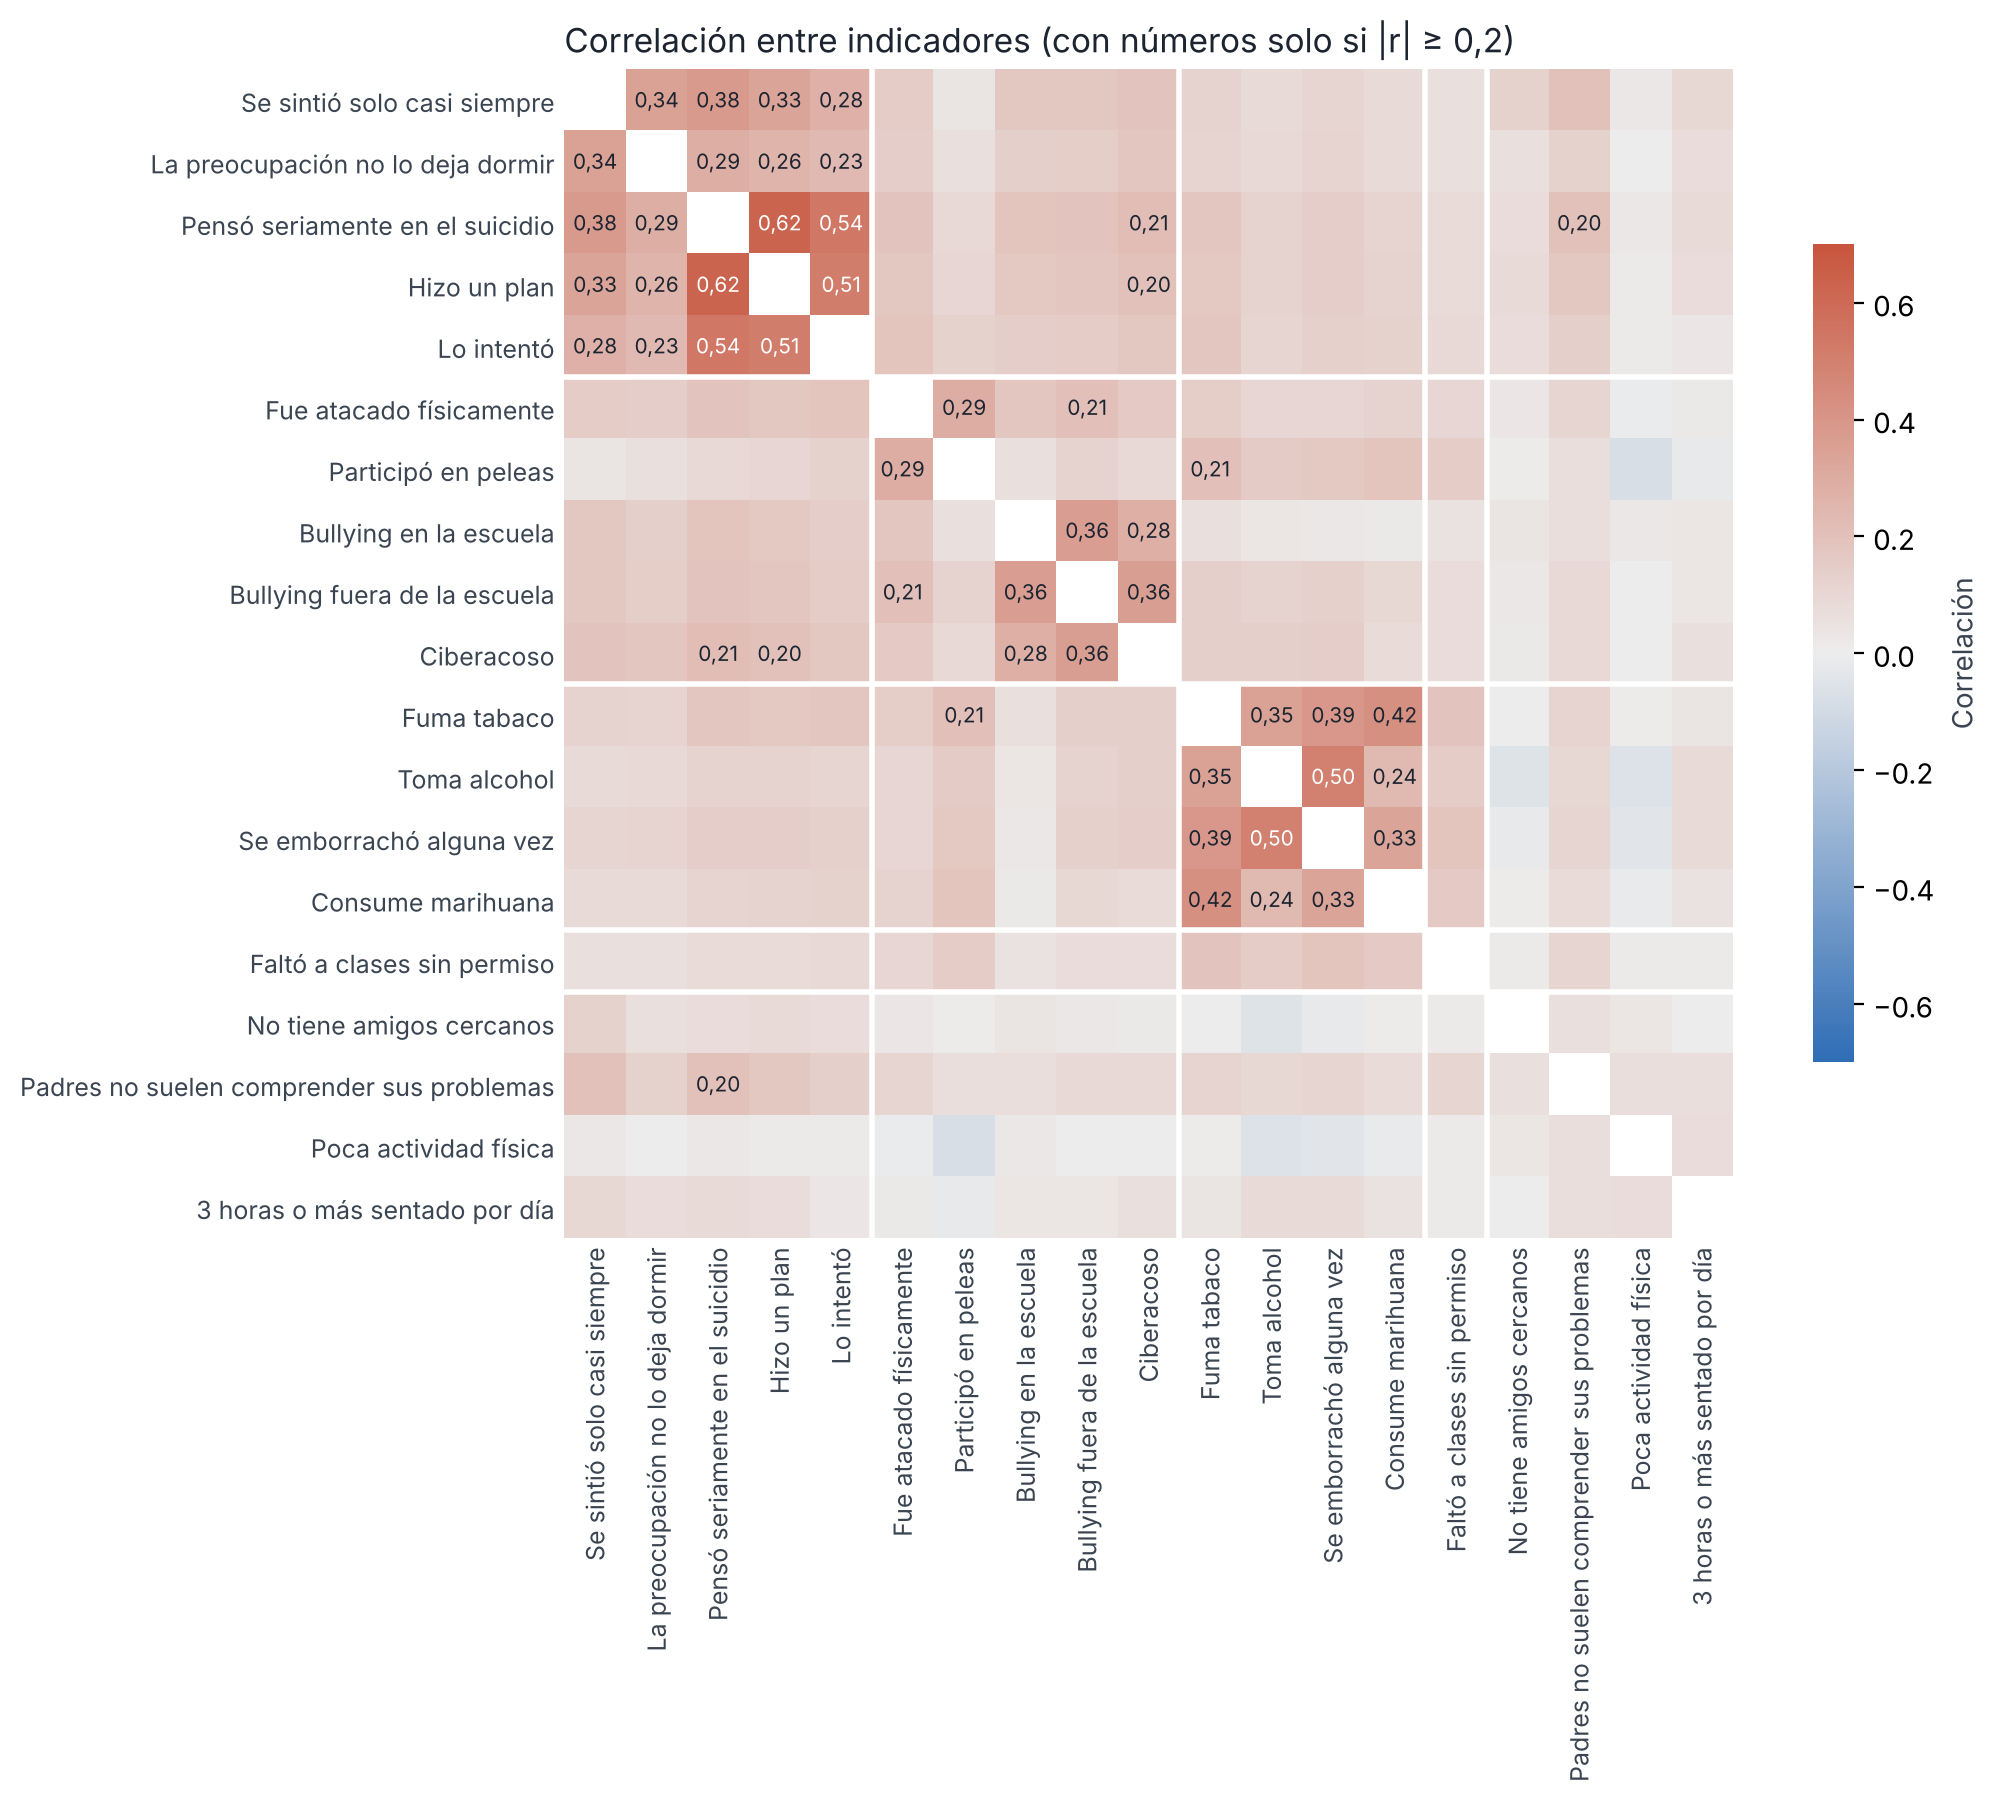

In [11]:
def graficar_correlacion(matriz: pd.DataFrame, etiquetas: list, cortes: list):
    # Escala divergente: azul (negativa), gris (cero), naranja (positiva)
    cmap = LinearSegmentedColormap.from_list('divergente', ['#2F6DB5', '#EDEDED', '#C8553D'])
    cmap.set_bad('#FFFFFF')
    valores = matriz.to_numpy().copy()
    np.fill_diagonal(valores, np.nan)

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(valores, cmap=cmap, vmin=-0.7, vmax=0.7)
    n = len(etiquetas)
    ax.set_xticks(range(n), etiquetas, rotation=90, fontsize=9, color='#3B4552')
    ax.set_yticks(range(n), etiquetas, fontsize=9, color='#3B4552')
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

    # solo etiquetamos las relaciones que importan (|r| >= 0,2)
    for i in range(n):
        for j in range(n):
            r = valores[i, j]
            if not np.isnan(r) and abs(r) >= 0.2:
                ax.text(j, i, f'{r:.2f}'.replace('.', ','), ha='center', va='center', fontsize=7.5,
                        color='white' if abs(r) >= 0.45 else '#1B2430')

    # separadores entre dimensiones
    for c in cortes:
        ax.axhline(c - 0.5, color='white', linewidth=2)
        ax.axvline(c - 0.5, color='white', linewidth=2)

    cbar = fig.colorbar(im, ax=ax, shrink=0.7)
    cbar.outline.set_visible(False)
    cbar.set_label('Correlación', color='#3B4552')
    ax.set_title('Correlación entre indicadores (con números solo si |r| ≥ 0,2)', loc='left', fontsize=12, color='#1B2430')
    plt.tight_layout()
    plt.show()

# cortes: fin de salud mental (5), violencia (10), consumo (14), escuela (15)
graficar_correlacion(correlacion, etiquetas, cortes=[5, 10, 14, 15])

**Cómo leerla.** Se ven tres bloques que van juntos:

* **Malestar emocional**: soledad, preocupación, ideación, plan e intento (la más fuerte es ideación con plan).
* **Violencia entre pares**: bullying en y fuera de la escuela y ciberacoso.
* **Consumo**: tabaco, alcohol, borracheras y marihuana, y cerca las peleas y las faltas a clase.

Este es el primer indicio de que vale la pena agrupar: si las problemáticas fueran independientes, no habría "perfiles" que encontrar.

In [12]:
print('Correlación máxima de cada candidata con los 15 indicadores:')
print(correlacion.loc[list(CANDIDATAS), COLUMNAS_MODELO].abs().max(axis=1).round(2).to_string())

Correlación máxima de cada candidata con los 15 indicadores:
sin_amigos              0.12
padres_no_comprenden    0.20
poca_actividad          0.08
sedentario              0.10


## 8. Variables que quedan afuera del modelo y por qué

In [13]:
vacios = lambda col: round(base[col].isna().mean() * 100, 1)
max_amigos = correlacion.loc['sin_amigos', COLUMNAS_MODELO].abs().max()

motivos = pd.DataFrame([
    ('No tiene amigos cercanos', round(porcentaje(base, 'qn27'), 1), vacios('qn27'),
     f'No se relaciona con los indicadores (correlación máxima {max_amigos:.2f}). Queda para cruzar.'.replace('.', ',', 1)),
    ('Padres no suelen comprender sus problemas', round(porcentaje(base, 'qn56', 2), 1), vacios('qn56'),
     'Le pasa a más de la mitad y en una prueba de k-means formaba un grupo ella sola. Queda para cruzar.'),
    ('Poca actividad física', round(porcentaje(base, 'qnpa5g', 2), 1), vacios('qnpa5g'),
     'Le pasa a la gran mayoría, así que no distingue grupos y taparía al resto.'),
    ('3 horas o más sentado', round(porcentaje(base, 'qn52'), 1), vacios('qn52'),
     'Le pasa a más de la mitad, mismo problema.'),
    ('Sobrepeso', round(porcentaje(base, 'qnowtg'), 1), vacios('qnowtg'),
     'Demasiados vacíos (sale de la estatura y el peso declarados).'),
    ('Relaciones antes de los 14 años', round(porcentaje(base, 'qn45'), 1), vacios('qn45'),
     'Solo la responde quien tuvo relaciones, el resto queda vacío.'),
], columns=['Variable', 'Le pasa a (%)', 'Vacíos (%)', 'Motivo'])
motivos

,Variable,Le pasa a (%),Vacíos (%),Motivo
0,No tiene amigos cercanos,5.6,1.9,No se relaciona con los indicadores (correlaci...
1,Padres no suelen comprender sus problemas,58.6,4.1,Le pasa a más de la mitad y en una prueba de k...
2,Poca actividad física,71.1,2.5,"Le pasa a la gran mayoría, así que no distingu..."
3,3 horas o más sentado,55.3,2.9,"Le pasa a más de la mitad, mismo problema."
4,Sobrepeso,30.3,36.6,Demasiados vacíos (sale de la estatura y el pe...
5,Relaciones antes de los 14 años,35.9,63.5,"Solo la responde quien tuvo relaciones, el res..."


**Pregunta para pensar.** Si una variable la tiene el 70% de los estudiantes, ¿por qué molesta en el k-means?

<details><summary>Ver respuesta</summary>

Porque el algoritmo agrupa por diferencias. Una variable tan extendida parte la base en "los que la tienen" y "los que no", y como pesa lo mismo que cualquier otra en la distancia, puede terminar separando grupos por ese rasgo en lugar de por combinaciones de problemas más informativas. Además, para la decisión no sirve: una acción para "el 70% de los chicos" es una acción para todos.
</details>

## 9. Variables de cruce

Estas **no entran al k-means**. Las guardamos para después cruzarlas con los grupos (tablas de perfil por edad, sexo, provincia, escuela y familia). Si entraran al modelo, los grupos ya vendrían separados por ellas y no podríamos descubrir la relación.

In [14]:
base['sexo'] = base['q2'].map(SEXO_POR_CODIGO)
base['hambre'] = a_binaria(base['qn6'])          # pasó hambre la mayoría de las veces o siempre
# sin_amigos y padres_no_comprenden ya están calculadas en el paso 7

COLUMNAS_CRUCE = ['provincia', 'provincia_deducida', 'escuela', 'edad', 'sexo',
                  'padres_no_comprenden', 'hambre', 'sin_amigos']
base[COLUMNAS_CRUCE].head()

,provincia,provincia_deducida,escuela,edad,sexo,padres_no_comprenden,hambre,sin_amigos
0,Buenos Aires,False,201801010-19,13,Mujer,0.0,0.0,0.0
1,Buenos Aires,False,201801010-19,13,Mujer,0.0,0.0,0.0
2,Buenos Aires,False,201801010-19,14,Varón,0.0,0.0,0.0
3,Buenos Aires,False,201801010-19,16,Varón,NaN,0.0,0.0
4,Buenos Aires,False,201801010-19,13,Mujer,0.0,0.0,0.0


## 10. Base preprocesada

In [15]:
preprocesado = base.loc[completas, ['record', 'weight'] + COLUMNAS_CRUCE + COLUMNAS_MODELO].copy()
preprocesado[COLUMNAS_MODELO] = preprocesado[COLUMNAS_MODELO].astype(int)

assert preprocesado[COLUMNAS_MODELO].isin([0, 1]).all().all()
assert preprocesado[COLUMNAS_MODELO].notna().all().all()

print(f'{len(preprocesado):,} estudiantes · {len(COLUMNAS_MODELO)} indicadores · '
      f"{preprocesado['provincia'].nunique()} provincias · {preprocesado['escuela'].nunique()} escuelas".replace(',', '.'))

resumen = pd.DataFrame({
    'Indicador': [VARIABLES_MODELO[c][1] for c in COLUMNAS_MODELO],
    'Dimensión': [VARIABLES_MODELO[c][2] for c in COLUMNAS_MODELO],
    '% del país': [round(100 * np.average(preprocesado[c], weights=preprocesado['weight']), 1) for c in COLUMNAS_MODELO],
})
resumen

47.945 estudiantes · 15 indicadores · 24 provincias · 557 escuelas


,Indicador,Dimensión,% del país
0,Se sintió solo casi siempre,Salud mental,16.7
1,La preocupación no lo deja dormir,Salud mental,12.9
2,Pensó seriamente en el suicidio,Salud mental,21.1
3,Hizo un plan,Salud mental,16.4
4,Lo intentó,Salud mental,14.2
5,Fue atacado físicamente,Violencia,16.7
6,Participó en peleas,Violencia,23.3
7,Bullying en la escuela,Violencia,21.2
8,Bullying fuera de la escuela,Violencia,20.9
9,Ciberacoso,Violencia,21.4


In [16]:
preprocesado.to_csv('emse_preprocesado.csv', index=False)
print('Guardado: emse_preprocesado.csv')

# Para bajarlo a tu compu desde Colab:
# from google.colab import files; files.download('emse_preprocesado.csv')

Guardado: emse_preprocesado.csv


## Qué sigue

En la **etapa 2** usamos `emse_preprocesado.csv` para elegir la cantidad de grupos (método del codo y silueta) y entrenar el k-means con los pesos.

**Resumen de la etapa 1**

* De 56.981 estudiantes nos quedamos con los de 13 a 17 años y, de esos, con los que respondieron los 15 indicadores.
* Los indicadores quedaron en 0/1 y los porcentajes coinciden con los oficiales.
* La matriz de correlación muestra tres bloques de problemáticas que van juntas, que es la base para buscar perfiles.
* Provincia, escuela, edad, sexo y familia quedaron aparte para los cruces.